# Tech Challenge - Fase 2
## Ajuste de Threshold e Explicabilidade do Modelo

Neste notebook será realizada uma análise do limiar de decisão (threshold) do modelo otimizado pelo Algoritmo Genético.

O objetivo é avaliar se diferentes thresholds podem reduzir a quantidade de falsos negativos, mantendo um equilíbrio adequado entre Recall, Precision e F1-score.

Após a definição do threshold, será utilizada a técnica SHAP para analisar quais características mais influenciam as previsões do modelo.

In [1]:
from pathlib import Path

import json
import joblib
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_predict
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

SEMENTE = 42

np.random.seed(SEMENTE)

print("Bibliotecas carregadas com sucesso.")

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Bibliotecas carregadas com sucesso.


In [2]:
def localizar_arquivo(caminhos):
    for caminho in caminhos:
        if caminho.exists():
            return caminho

    raise FileNotFoundError(
        "Nenhum dos caminhos informados foi encontrado."
    )


pasta_atual = Path.cwd()

caminho_dados = localizar_arquivo([
    Path("/app/data/data.csv"),
    pasta_atual / "data" / "data.csv",
    pasta_atual.parent / "data" / "data.csv"
])

caminho_modelo = localizar_arquivo([
    Path("/app/models/modelo_ga_fase2.joblib"),
    pasta_atual / "models" / "modelo_ga_fase2.joblib",
    pasta_atual.parent / "models" / "modelo_ga_fase2.joblib"
])

print("Dataset:")
print(caminho_dados)

print()

print("Modelo:")
print(caminho_modelo)

Dataset:
/app/data/data.csv

Modelo:
/app/models/modelo_ga_fase2.joblib


In [3]:
dados = pd.read_csv(
    caminho_dados
)

df = dados.copy()

df = df.drop(
    columns=[
        "id",
        "Unnamed: 32"
    ],
    errors="ignore"
)

df["diagnosis"] = df["diagnosis"].map({
    "B": 0,
    "M": 1
})

df["diagnosis"] = (
    df["diagnosis"].astype(int)
)

df = (
    df.drop_duplicates()
    .reset_index(drop=True)
)

X = df.drop(
    columns=["diagnosis"]
)

y = df["diagnosis"]

X_train, X_test, y_train, y_test = (
    train_test_split(
        X,
        y,
        test_size=0.20,
        stratify=y,
        random_state=SEMENTE
    )
)

print(
    f"Treino: {len(X_train)} registros"
)

print(
    f"Teste: {len(X_test)} registros"
)

print(
    f"Variáveis: {X.shape[1]}"
)

Treino: 455 registros
Teste: 114 registros
Variáveis: 30


In [4]:
modelo_ga = joblib.load(
    caminho_modelo
)

print(
    "Modelo do Algoritmo Genético carregado."
)

print()

print(
    modelo_ga.named_steps["modelo"]
)

Modelo do Algoritmo Genético carregado.

LogisticRegression(C=0.1, class_weight='balanced', max_iter=5000, penalty='l2',
                   random_state=42, solver='liblinear')


## Ajuste do threshold

Por padrão, modelos de classificação binária utilizam um threshold de `0,50`. Isso significa que probabilidades iguais ou superiores a 50% são classificadas como malignas.

Em um contexto de diagnóstico, entretanto, falsos negativos possuem especial importância, pois representam casos realmente malignos classificados como benignos.

Para evitar utilizar o conjunto de teste durante a escolha do threshold, serão geradas probabilidades fora da amostra (out-of-fold) utilizando validação cruzada apenas sobre os dados de treinamento.

O threshold será escolhido utilizando o F2-score, métrica que atribui maior importância ao Recall do que à Precision.

In [5]:
validacao_cruzada = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEMENTE
)

probabilidades_validacao = (
    cross_val_predict(
        modelo_ga,
        X_train,
        y_train,
        cv=validacao_cruzada,
        method="predict_proba",
        n_jobs=-1
    )[:, 1]
)

print(
    "Probabilidades out-of-fold geradas."
)

print(
    f"Quantidade: "
    f"{len(probabilidades_validacao)}"
)

Probabilidades out-of-fold geradas.
Quantidade: 455


In [6]:
thresholds = np.arange(
    0.20,
    0.61,
    0.01
)

resultados_threshold = []

for threshold in thresholds:

    previsoes = (
        probabilidades_validacao
        >= threshold
    ).astype(int)

    resultados_threshold.append({
        "threshold":
            threshold,

        "precision":
            precision_score(
                y_train,
                previsoes,
                zero_division=0
            ),

        "recall":
            recall_score(
                y_train,
                previsoes,
                zero_division=0
            ),

        "f1":
            f1_score(
                y_train,
                previsoes,
                zero_division=0
            ),

        "f2":
            fbeta_score(
                y_train,
                previsoes,
                beta=2,
                zero_division=0
            )
    })


df_threshold = pd.DataFrame(
    resultados_threshold
)

display(
    df_threshold.round(4)
)

,threshold,precision,recall,f1,f2
0,0.20,0.8164,0.9941,0.8966,0.9526
1,0.21,0.8284,0.9941,0.9037,0.9559
2,0.22,0.8276,0.9882,0.9008,0.9513
3,0.23,0.8442,0.9882,0.9106,0.9556
4,0.24,0.8520,0.9824,0.9126,0.9532
5,0.25,0.8608,0.9824,0.9176,0.9554
6,0.26,0.8743,0.9824,0.9252,0.9587
7,0.27,0.8789,0.9824,0.9278,0.9598
8,0.28,0.8836,0.9824,0.9304,0.9609
9,0.29,0.8978,0.9824,0.9382,0.9642


In [7]:
melhor_linha = (
    df_threshold
    .sort_values(
        by=[
            "f2",
            "recall",
            "f1"
        ],
        ascending=False
    )
    .iloc[0]
)

threshold_otimizado = float(
    melhor_linha[
        "threshold"
    ]
)

print(
    "=== THRESHOLD SELECIONADO ==="
)

print(
    f"Threshold: "
    f"{threshold_otimizado:.2f}"
)

print(
    f"Precision: "
    f"{melhor_linha['precision']:.4f}"
)

print(
    f"Recall: "
    f"{melhor_linha['recall']:.4f}"
)

print(
    f"F1-score: "
    f"{melhor_linha['f1']:.4f}"
)

print(
    f"F2-score: "
    f"{melhor_linha['f2']:.4f}"
)

=== THRESHOLD SELECIONADO ===
Threshold: 0.34
Precision: 0.9382
Recall: 0.9824
F1-score: 0.9598
F2-score: 0.9732


In [8]:
comparacao_thresholds = (
    df_threshold[
        df_threshold[
            "threshold"
        ].round(2).isin([
            0.30,
            0.50,
            round(
                threshold_otimizado,
                2
            )
        ])
    ]
    .drop_duplicates(
        subset=["threshold"]
    )
)

display(
    comparacao_thresholds.round(4)
)

,threshold,precision,recall,f1,f2
10,0.30,0.9027,0.9824,0.9408,0.9653
14,0.34,0.9382,0.9824,0.9598,0.9732
30,0.50,0.9760,0.9588,0.9674,0.9622


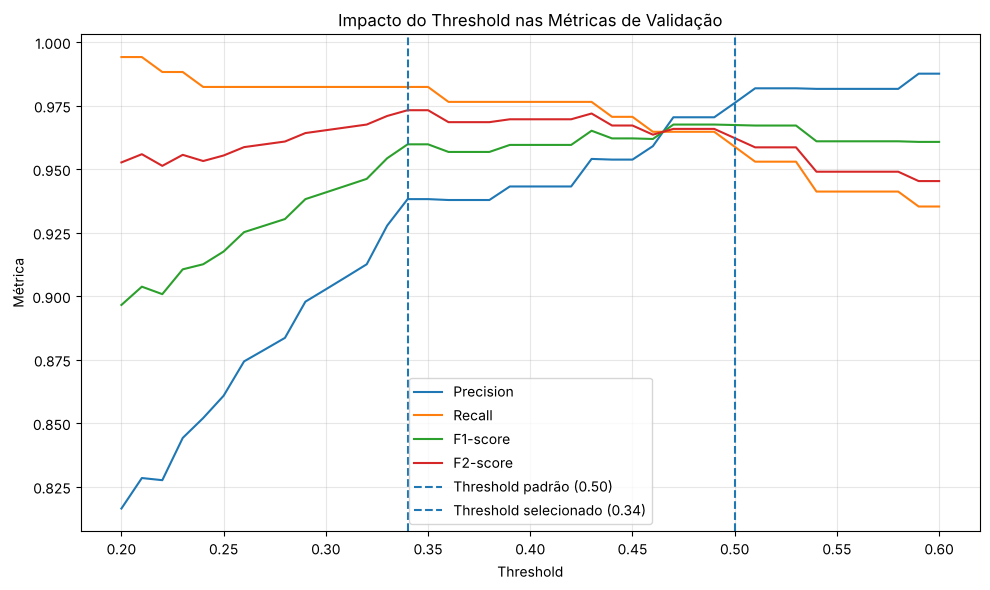

In [9]:
pasta_resultados = localizar_arquivo([
    Path("/app/results"),
    pasta_atual / "results",
    pasta_atual.parent / "results"
])

plt.figure(
    figsize=(10, 6)
)

plt.plot(
    df_threshold["threshold"],
    df_threshold["precision"],
    label="Precision"
)

plt.plot(
    df_threshold["threshold"],
    df_threshold["recall"],
    label="Recall"
)

plt.plot(
    df_threshold["threshold"],
    df_threshold["f1"],
    label="F1-score"
)

plt.plot(
    df_threshold["threshold"],
    df_threshold["f2"],
    label="F2-score"
)

plt.axvline(
    x=0.50,
    linestyle="--",
    label="Threshold padrão (0.50)"
)

plt.axvline(
    x=threshold_otimizado,
    linestyle="--",
    label=(
        f"Threshold selecionado "
        f"({threshold_otimizado:.2f})"
    )
)

plt.xlabel(
    "Threshold"
)

plt.ylabel(
    "Métrica"
)

plt.title(
    "Impacto do Threshold "
    "nas Métricas de Validação"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    pasta_resultados /
    "03_analise_threshold.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Avaliação do threshold no conjunto de teste

Após selecionar o threshold utilizando exclusivamente os dados de treinamento, será realizada a comparação final no conjunto de teste.

Serão comparados o threshold padrão de `0,50` e o threshold selecionado durante a validação.

O objetivo principal é verificar o impacto da alteração sobre Recall, F1-score e quantidade de falsos negativos.

In [10]:
probabilidades_teste = (
    modelo_ga.predict_proba(
        X_test
    )[:, 1]
)

In [11]:
def avaliar_threshold(
    threshold
):

    previsoes = (
        probabilidades_teste
        >= threshold
    ).astype(int)

    matriz = confusion_matrix(
        y_test,
        previsoes
    )

    tn, fp, fn, tp = (
        matriz.ravel()
    )

    return {
        "threshold":
            threshold,

        "accuracy":
            accuracy_score(
                y_test,
                previsoes
            ),

        "precision":
            precision_score(
                y_test,
                previsoes,
                zero_division=0
            ),

        "recall":
            recall_score(
                y_test,
                previsoes,
                zero_division=0
            ),

        "f1":
            f1_score(
                y_test,
                previsoes,
                zero_division=0
            ),

        "roc_auc":
            roc_auc_score(
                y_test,
                probabilidades_teste
            ),

        "tn":
            int(tn),

        "fp":
            int(fp),

        "fn":
            int(fn),

        "tp":
            int(tp)
    }

In [12]:
resultado_padrao = (
    avaliar_threshold(
        0.50
    )
)

resultado_otimizado = (
    avaliar_threshold(
        threshold_otimizado
    )
)

comparacao_teste = pd.DataFrame([
    resultado_padrao,
    resultado_otimizado
])

display(
    comparacao_teste.round(4)
)

,threshold,accuracy,precision,recall,f1,roc_auc,tn,fp,fn,tp
0,0.50,0.9912,1.0000,0.9762,0.9880,0.9977,72,0,1,41
1,0.34,0.9474,0.8913,0.9762,0.9318,0.9977,67,5,1,41


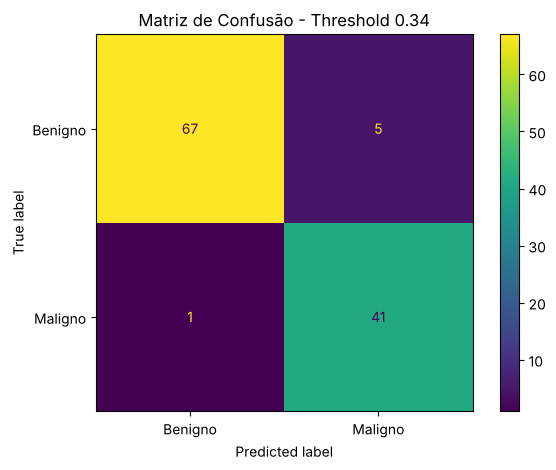

In [13]:
previsoes_otimizadas = (
    probabilidades_teste
    >= threshold_otimizado
).astype(int)

matriz_otimizada = confusion_matrix(
    y_test,
    previsoes_otimizadas
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=
        matriz_otimizada,

    display_labels=[
        "Benigno",
        "Maligno"
    ]
)

disp.plot()

plt.title(
    "Matriz de Confusão - "
    f"Threshold {threshold_otimizado:.2f}"
)

plt.tight_layout()

plt.savefig(
    pasta_resultados /
    "04_matriz_confusao_threshold.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [14]:
configuracao_threshold = {
    "threshold_padrao":
        0.50,

    "threshold_otimizado":
        threshold_otimizado,

    "criterio_selecao":
        "Maior F2-score em validação cruzada",

    "resultado_padrao_teste":
        resultado_padrao,

    "resultado_otimizado_teste":
        resultado_otimizado
}


with open(
    pasta_resultados /
    "threshold_otimizado.json",
    "w",
    encoding="utf-8"
) as arquivo:

    json.dump(
        configuracao_threshold,
        arquivo,
        indent=4,
        ensure_ascii=False
    )

print(
    "Configuração do threshold salva."
)

Configuração do threshold salva.


## Análise da recomendação da avaliação da Fase 1: threshold 0,30

Na avaliação da Fase 1, foi recomendado reduzir o threshold da Regressão Logística de 0,50 para 0,30 e verificar se os 2 falsos negativos restantes no conjunto de teste seriam eliminados.

A análise é feita para os dois modelos: o modelo final da Fase 1 (GridSearchCV) e o modelo otimizado pelo Algoritmo Genético.

Como utiliza o conjunto de teste, esta etapa é uma **análise de sensibilidade**. Ela não é usada para escolher o threshold, que continua sendo definido somente com validação cruzada sobre o treino.

In [15]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

caminho_baseline = localizar_arquivo([
    Path("/app/results/baseline_fase1.json"),
    pasta_atual / "results" / "baseline_fase1.json",
    pasta_atual.parent / "results" / "baseline_fase1.json"
])

with open(caminho_baseline, "r", encoding="utf-8") as arquivo:
    baseline_fase1 = json.load(arquivo)

hiperparametros_fase1 = baseline_fase1.get(
    "hiperparametros",
    {"C": 1, "class_weight": "balanced"}
)

# Reconstrução do modelo final da Fase 1 (mesmos dados de treino)
modelo_fase1 = Pipeline([
    ("padronizacao", StandardScaler()),
    ("modelo", LogisticRegression(
        **hiperparametros_fase1,
        max_iter=5000,
        random_state=SEMENTE
    ))
])

modelo_fase1.fit(X_train, y_train)

probabilidades_teste_fase1 = modelo_fase1.predict_proba(X_test)[:, 1]

print("Modelo da Fase 1 reconstruído:", hiperparametros_fase1)

Modelo da Fase 1 reconstruído: {'C': 1, 'class_weight': 'balanced'}


In [16]:
def metricas_por_threshold(probabilidades, threshold):

    previsoes = (probabilidades >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_test, previsoes).ravel()

    return {
        "threshold": threshold,
        "recall": recall_score(y_test, previsoes, zero_division=0),
        "precision": precision_score(y_test, previsoes, zero_division=0),
        "f1": f1_score(y_test, previsoes, zero_division=0),
        "fn": int(fn),
        "fp": int(fp)
    }


modelos_comparacao = {
    "Fase 1 (GridSearchCV)": probabilidades_teste_fase1,
    "Fase 2 (Algoritmo Genético)": probabilidades_teste
}

thresholds_analise = [0.50, round(threshold_otimizado, 2), 0.30, 0.20]

analise_professor = pd.DataFrame([
    {"modelo": nome, **metricas_por_threshold(probabilidades, threshold)}
    for nome, probabilidades in modelos_comparacao.items()
    for threshold in thresholds_analise
])

display(analise_professor.round(4))

,modelo,threshold,recall,precision,f1,fn,fp
0,Fase 1 (GridSearchCV),0.50,0.9524,0.9756,0.9639,2,1
1,Fase 1 (GridSearchCV),0.34,0.9524,0.9756,0.9639,2,1
2,Fase 1 (GridSearchCV),0.30,0.9524,0.9524,0.9524,2,2
3,Fase 1 (GridSearchCV),0.20,0.9762,0.9111,0.9425,1,4
4,Fase 2 (Algoritmo Genético),0.50,0.9762,1.0000,0.9880,1,0
5,Fase 2 (Algoritmo Genético),0.34,0.9762,0.8913,0.9318,1,5
6,Fase 2 (Algoritmo Genético),0.30,0.9762,0.8913,0.9318,1,5
7,Fase 2 (Algoritmo Genético),0.20,1.0000,0.8571,0.9231,0,7


In [17]:
# Qual threshold seria necessário para zerar os falsos negativos?

limites_fn_zero = []

for nome, probabilidades in modelos_comparacao.items():

    probabilidades_malignos = np.sort(
        probabilidades[y_test.values == 1]
    )

    limite = float(probabilidades_malignos[0])
    resultado = metricas_por_threshold(probabilidades, limite)

    limites_fn_zero.append({
        "modelo": nome,
        "menores_prob_malignos": np.round(probabilidades_malignos[:3], 4).tolist(),
        "threshold_para_fn_zero": round(limite, 4),
        "fp_resultante": resultado["fp"],
        "precision_resultante": round(resultado["precision"], 4)
    })

display(pd.DataFrame(limites_fn_zero))

,modelo,menores_prob_malignos,threshold_para_fn_zero,fp_resultante,precision_resultante
0,Fase 1 (GridSearchCV),"[0.0882, 0.2736, 0.5633]",0.0882,9,0.8235
1,Fase 2 (Algoritmo Genético),"[0.2237, 0.5189, 0.6523]",0.2237,7,0.8571


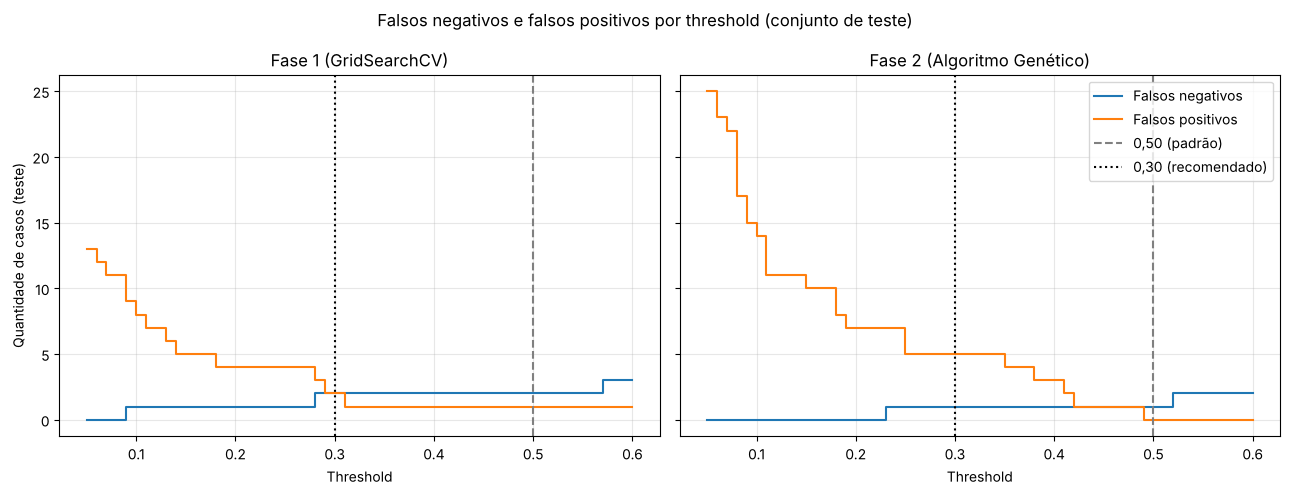

In [18]:
faixa_thresholds = np.arange(0.05, 0.61, 0.01)

fig, eixos = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

for eixo, (nome, probabilidades) in zip(eixos, modelos_comparacao.items()):

    curva = pd.DataFrame([
        metricas_por_threshold(probabilidades, t)
        for t in faixa_thresholds
    ])

    eixo.step(curva["threshold"], curva["fn"], where="post", label="Falsos negativos")
    eixo.step(curva["threshold"], curva["fp"], where="post", label="Falsos positivos")

    eixo.axvline(0.50, linestyle="--", color="gray", label="0,50 (padrão)")
    eixo.axvline(0.30, linestyle=":", color="black", label="0,30 (recomendado)")

    eixo.set_title(nome)
    eixo.set_xlabel("Threshold")
    eixo.grid(alpha=0.3)

eixos[0].set_ylabel("Quantidade de casos (teste)")
eixos[1].legend()

plt.suptitle("Falsos negativos e falsos positivos por threshold (conjunto de teste)")
plt.tight_layout()

plt.savefig(
    pasta_resultados / "08_sensibilidade_threshold_teste.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

analise_professor.to_csv(
    pasta_resultados / "analise_threshold_030.csv",
    index=False
)

### Resultado da análise

- **Modelo da Fase 1:** com threshold 0,30, os 2 falsos negativos **não foram eliminados** (FN = 2) e surgiu 1 falso positivo adicional. Um dos casos malignos recebeu probabilidade de apenas 0,088; zerar os falsos negativos exigiria threshold ≤ 0,088, com 9 falsos positivos (Precision 0,82).
- **Modelo otimizado pelo Algoritmo Genético:** já parte de 1 falso negativo com o threshold padrão. Com 0,30 (ou 0,34), esse falso negativo se mantém e surgem 5 falsos positivos. O caso restante recebeu probabilidade 0,224; zerar os falsos negativos exigiria threshold ≤ 0,22, com 7 falsos positivos (Precision 0,86).
- **Conclusão:** reduzir o threshold para 0,30 não elimina os falsos negativos em nenhum dos dois modelos. A redução efetiva de falsos negativos (2 → 1) veio da otimização dos hiperparâmetros, e não do threshold. Os casos restantes recebem probabilidades muito abaixo do limiar, ou seja, são casos atípicos para o modelo (analisados a seguir com SHAP).
- Um threshold próximo de 0,22 zeraria os falsos negativos do modelo otimizado neste conjunto de teste, mas esse valor foi encontrado observando o próprio teste; adotá-lo sem validação em novos dados seria um sobreajuste ao conjunto de teste. Por isso, o threshold continua sendo o definido na validação cruzada (0,34).

## Explicabilidade com SHAP

Após otimizar o modelo e analisar o threshold de decisão, será utilizada a técnica SHAP para interpretar as previsões.

O SHAP estima a contribuição de cada variável para a saída do modelo, permitindo identificar quais características aumentam ou reduzem a probabilidade de classificação como maligno.

Serão analisadas tanto a importância global das variáveis quanto a explicação de uma previsão individual.

In [19]:
scaler = (
    modelo_ga.named_steps[
        "padronizacao"
    ]
)

regressao = (
    modelo_ga.named_steps[
        "modelo"
    ]
)

X_train_padronizado = pd.DataFrame(
    scaler.transform(
        X_train
    ),
    columns=X_train.columns,
    index=X_train.index
)

X_test_padronizado = pd.DataFrame(
    scaler.transform(
        X_test
    ),
    columns=X_test.columns,
    index=X_test.index
)

print(
    X_train_padronizado.shape
)

print(
    X_test_padronizado.shape
)

(455, 30)
(114, 30)


In [20]:
explicador_shap = (
    shap.LinearExplainer(
        regressao,
        X_train_padronizado
    )
)

valores_shap = (
    explicador_shap(
        X_test_padronizado
    )
)

print(
    "SHAP calculado com sucesso."
)

print(
    valores_shap.values.shape
)

Background dataset has 455 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=455 when initializing the masker.


SHAP calculado com sucesso.
(114, 30)


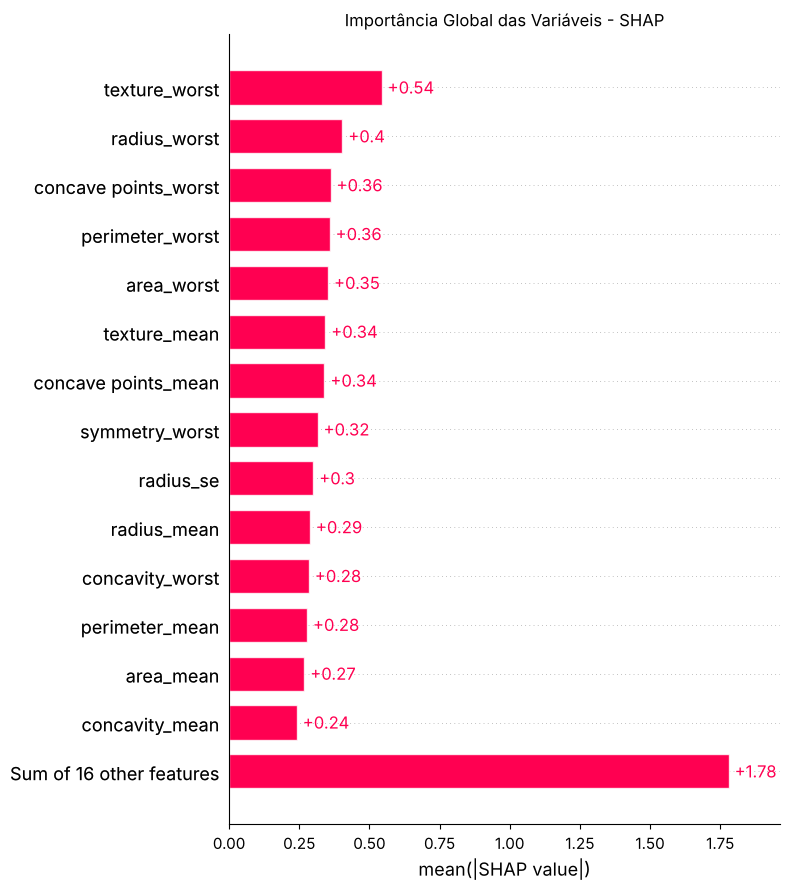

In [21]:
shap.plots.bar(
    valores_shap,
    max_display=15,
    show=False
)

plt.title(
    "Importância Global das Variáveis - SHAP"
)

plt.tight_layout()

plt.savefig(
    pasta_resultados /
    "05_shap_importancia_global.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

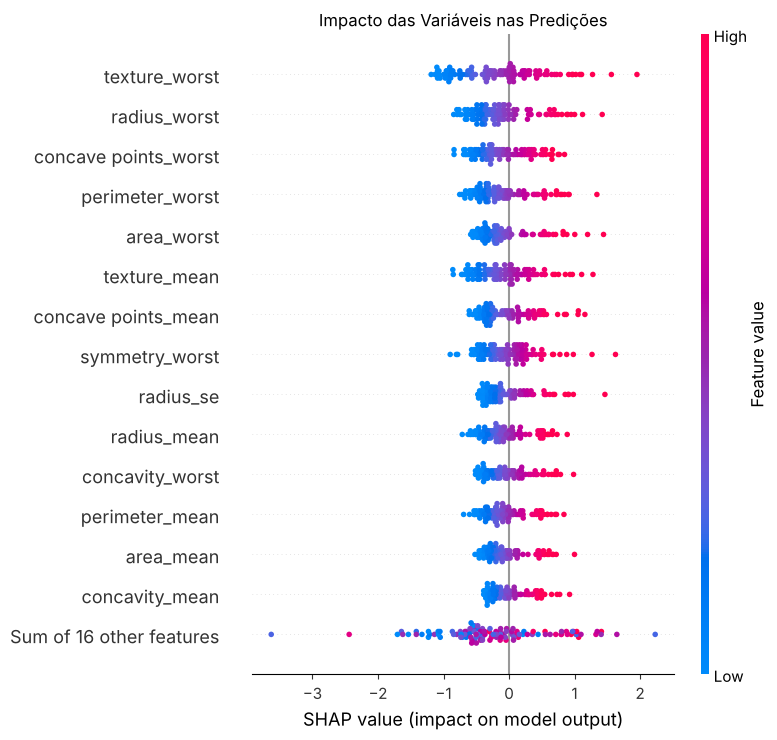

In [22]:
shap.plots.beeswarm(
    valores_shap,
    max_display=15,
    show=False
)

plt.title(
    "Impacto das Variáveis nas Predições"
)

plt.tight_layout()

plt.savefig(
    pasta_resultados /
    "06_shap_impacto_variaveis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [23]:
indices_malignos = np.where(
    previsoes_otimizadas == 1
)[0]

indice_exemplo = int(
    indices_malignos[0]
)

print(
    "Índice do exemplo:",
    indice_exemplo
)

print(
    "Probabilidade de malignidade:"
)

print(
    f"{probabilidades_teste[indice_exemplo]:.4f}"
)

print(
    "Classe real:"
)

print(
    int(
        y_test.iloc[
            indice_exemplo
        ]
    )
)

Índice do exemplo: 1
Probabilidade de malignidade:
1.0000
Classe real:
1


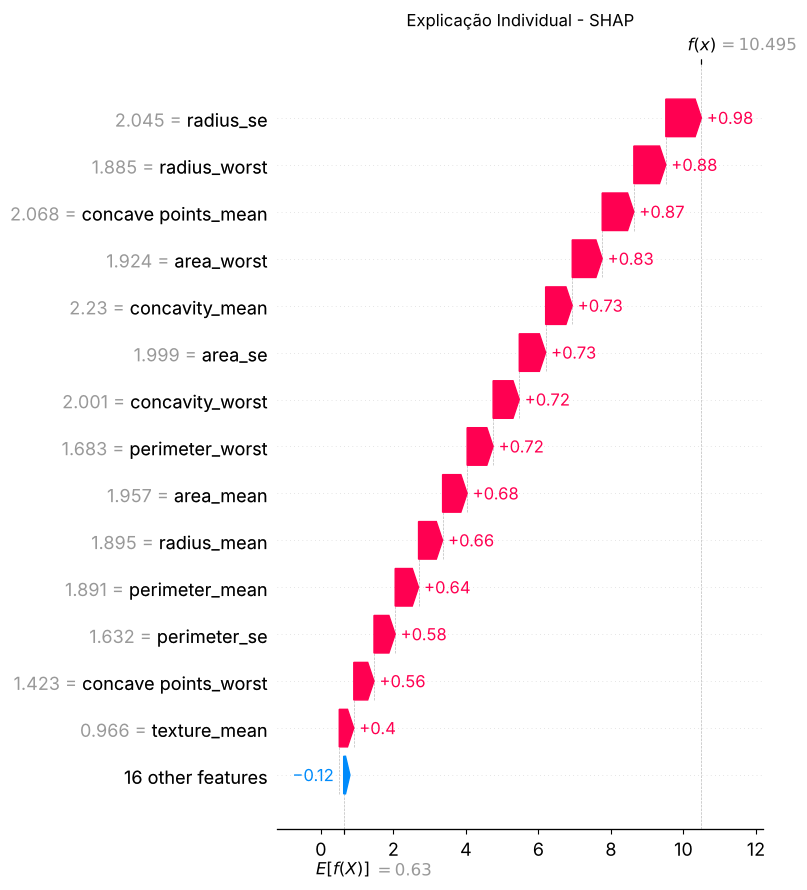

In [24]:
shap.plots.waterfall(
    valores_shap[
        indice_exemplo
    ],
    max_display=15,
    show=False
)

plt.title(
    "Explicação Individual - SHAP"
)

plt.tight_layout()

plt.savefig(
    pasta_resultados /
    "07_shap_explicacao_individual.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [25]:
importancia_media = np.abs(
    valores_shap.values
).mean(axis=0)

importancia_shap = pd.DataFrame({
    "variavel":
        X_test.columns,

    "importancia_media_shap":
        importancia_media
})

importancia_shap = (
    importancia_shap
    .sort_values(
        "importancia_media_shap",
        ascending=False
    )
)

display(
    importancia_shap.head(
        15
    )
)

importancia_shap.to_csv(
    pasta_resultados /
    "importancia_variaveis_shap.csv",
    index=False
)

,variavel,importancia_media_shap
21,texture_worst,0.543792
20,radius_worst,0.403651
27,concave points_worst,0.361740
22,perimeter_worst,0.358403
23,area_worst,0.352808
1,texture_mean,0.342873
7,concave points_mean,0.339866
28,symmetry_worst,0.315495
10,radius_se,0.300078
0,radius_mean,0.288084


## Análise do falso negativo restante

O modelo otimizado ainda classifica um caso maligno como benigno. O SHAP permite entender por que o modelo atribuiu baixa probabilidade a esse caso.

In [26]:
indices_falso_negativo = np.where(
    (y_test.values == 1) & (previsoes_otimizadas == 0)
)[0]

print(f"Falsos negativos com threshold {threshold_otimizado:.2f}: {len(indices_falso_negativo)}")

indice_fn = int(indices_falso_negativo[0])

print(f"Índice no teste: {indice_fn}")
print(f"Probabilidade de malignidade: {probabilidades_teste[indice_fn]:.4f}")

fatores_fn = pd.DataFrame({
    "variavel": X_test.columns,
    "valor": X_test.iloc[indice_fn].values,
    "percentil_no_treino": [
        round((X_train[coluna] <= X_test.iloc[indice_fn][coluna]).mean() * 100, 1)
        for coluna in X_test.columns
    ],
    "valor_shap": valores_shap.values[indice_fn]
})

fatores_fn = fatores_fn.reindex(
    fatores_fn["valor_shap"].abs().sort_values(ascending=False).index
)

display(fatores_fn.head(8).round(4))

Falsos negativos com threshold 0.34: 1
Índice no teste: 16
Probabilidade de malignidade: 0.2237


,variavel,valor,percentil_no_treino,valor_shap
21,texture_worst,20.8600,21.8,-0.5684
1,texture_mean,15.7900,20.9,-0.3670
10,radius_se,0.2787,39.3,-0.2349
28,symmetry_worst,0.2589,30.3,-0.2253
12,perimeter_se,1.9570,37.1,-0.1576
13,area_se,23.3500,46.2,-0.1510
23,area_worst,812.4000,62.4,-0.1292
3,area_mean,584.1000,56.0,-0.1121


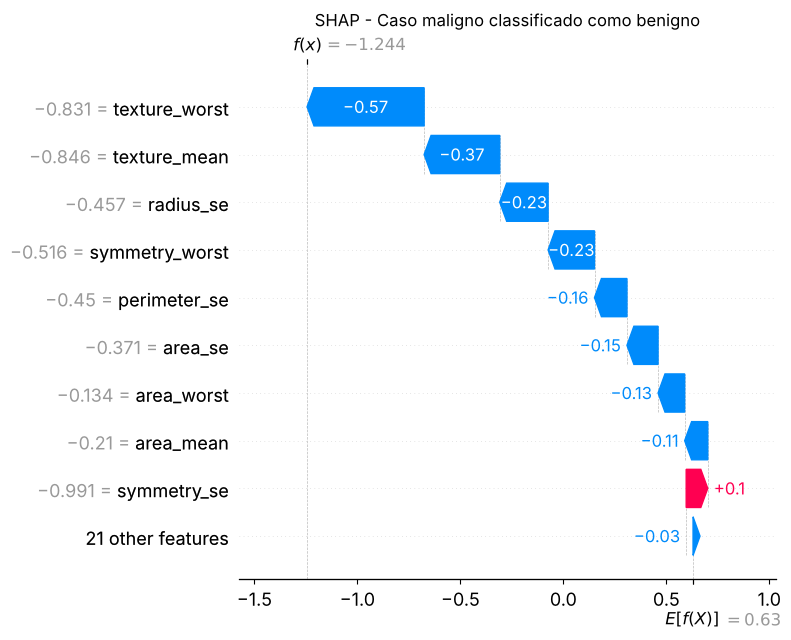

In [27]:
shap.plots.waterfall(
    valores_shap[indice_fn],
    max_display=10,
    show=False
)

plt.title("SHAP - Caso maligno classificado como benigno")
plt.tight_layout()

plt.savefig(
    pasta_resultados / "09_shap_falso_negativo.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Interpretação

O caso maligno não detectado possui **textura baixa**: `texture_worst` e `texture_mean` estão por volta do percentil 21 do conjunto de treino, e a textura é justamente a variável mais importante do modelo. As medidas de tamanho (`area_worst`, `area_mean`) estão próximas da mediana e não compensam esse efeito.

Ou seja, trata-se de um tumor maligno com perfil morfológico semelhante ao de tumores benignos nas variáveis que o modelo mais utiliza.

Casos assim mostram por que a classificação deve ser usada como apoio à decisão e não substitui a avaliação clínica. São também os casos em que dados adicionais, como textos clínicos e imagens (previstos para o Módulo 3), podem trazer informações que as 30 variáveis numéricas não capturam.

## Consistência da explicabilidade entre modelos

Na Fase 1, a consistência das explicações foi verificada comparando o SHAP da Regressão Logística com o do Random Forest.

Aqui a mesma verificação é feita entre o modelo da Fase 1 e o modelo otimizado pelo Algoritmo Genético: se as variáveis mais importantes se mantêm, a otimização mudou o desempenho sem alterar a lógica de decisão do modelo.

In [28]:
from scipy.stats import spearmanr

scaler_fase1 = modelo_fase1.named_steps["padronizacao"]
regressao_fase1 = modelo_fase1.named_steps["modelo"]

X_train_fase1 = pd.DataFrame(scaler_fase1.transform(X_train), columns=X_train.columns)
X_test_fase1 = pd.DataFrame(scaler_fase1.transform(X_test), columns=X_test.columns)

valores_shap_fase1 = shap.LinearExplainer(regressao_fase1, X_train_fase1)(X_test_fase1)

comparacao_shap = pd.DataFrame({
    "importancia_fase1": np.abs(valores_shap_fase1.values).mean(axis=0),
    "importancia_ga": np.abs(valores_shap.values).mean(axis=0)
}, index=X_test.columns)

comparacao_shap["ranking_fase1"] = comparacao_shap["importancia_fase1"].rank(ascending=False).astype(int)
comparacao_shap["ranking_ga"] = comparacao_shap["importancia_ga"].rank(ascending=False).astype(int)

comparacao_shap = comparacao_shap.sort_values("ranking_ga")

top10_fase1 = set(comparacao_shap.nsmallest(10, "ranking_fase1").index)
top10_ga = set(comparacao_shap.nsmallest(10, "ranking_ga").index)

correlacao, _ = spearmanr(comparacao_shap["importancia_fase1"], comparacao_shap["importancia_ga"])

display(comparacao_shap.head(10).round(4))

print(f"Variáveis em comum no top 10: {len(top10_fase1 & top10_ga)} de 10")
print(f"Correlação de Spearman entre os rankings (30 variáveis): {correlacao:.3f}")

comparacao_shap.to_csv(pasta_resultados / "comparacao_shap_fase1_vs_ga.csv")

Background dataset has 455 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=455 when initializing the masker.


,importancia_fase1,importancia_ga,ranking_fase1,ranking_ga
texture_worst,1.2787,0.5438,1,1
radius_worst,0.7163,0.4037,6,2
concave points_worst,0.6065,0.3617,9,3
perimeter_worst,0.5530,0.3584,10,4
area_worst,0.6883,0.3528,8,5
texture_mean,0.3537,0.3429,17,6
concave points_mean,0.7358,0.3399,4,7
symmetry_worst,0.7516,0.3155,3,8
radius_se,0.8078,0.3001,2,9
radius_mean,0.2432,0.2881,22,10


Variáveis em comum no top 10: 8 de 10
Correlação de Spearman entre os rankings (30 variáveis): 0.702


### Resultado

- 8 das 10 variáveis mais importantes são as mesmas nos dois modelos, e a correlação de Spearman entre as importâncias das 30 variáveis é de 0,70;
- `texture_worst` é a variável mais importante em ambos os modelos;
- As importâncias absolutas do modelo otimizado são menores porque o Algoritmo Genético escolheu uma regularização mais forte (C = 0,1 contra C = 1 na Fase 1). Com regularização mais forte, o peso fica mais distribuído entre variáveis correlacionadas, como raio, perímetro e área, em vez de concentrado em poucas variáveis.

A otimização manteve a lógica de decisão do modelo (textura, tamanho e concavidade); a principal diferença entre os modelos está na regularização.

## Conclusão

- O threshold de 0,34 foi selecionado com probabilidades out-of-fold no treino, pelo critério de maior F2-score, preservando o conjunto de teste.
- No teste, o threshold de 0,34 manteve 1 falso negativo e acrescentou 5 falsos positivos em relação ao threshold de 0,50.
- Atendendo à recomendação da avaliação da Fase 1, foi testado o threshold de 0,30: ele não elimina os falsos negativos em nenhum dos modelos. A redução de falsos negativos (2 → 1) veio da otimização por Algoritmo Genético.
- O SHAP identificou textura, tamanho e concavidade como as variáveis mais influentes, de forma consistente entre o modelo da Fase 1 e o modelo otimizado.
- A análise do falso negativo restante mostrou um tumor maligno com textura baixa, atípico para o modelo.

Essas informações são utilizadas no notebook 04 para fornecer contexto à LLM.